# LAB 07 — Transformer Text Classification

## 1. Mục tiêu và luồng xử lý

Notebook sử dụng bộ dữ liệu IMDb và quy trình tiền xử lý của LAB 05 để so sánh LSTM với Transformer Encoder. Phần attention kế thừa công thức Scaled Dot-Product Attention và cách tạo Query, Key, Value từ LAB 06. Transformer Encoder Block được ghép từ Multi-Head Self-Attention, residual connection, Layer Normalization và Feed-Forward Network.

**Luồng xử lý chính**

`IMDb text → Tokenizer → Vocabulary → Token IDs → Padding/Truncation → Embedding + Positional Encoding → Multi-Head Self-Attention → Add & Norm → Feed-Forward Network → Add & Norm → Masked Mean Pooling → Linear Classifier → Sentiment`

Nhãn dữ liệu: `0 = negative`, `1 = positive`.

## 2. Thiết lập thực nghiệm

- Dataset: IMDb, cùng nguồn dữ liệu với LAB 05 và LAB 06.
- Chia tập: train/validation/test; validation được tách từ tập train bằng `stratify`.
- Vocabulary chỉ được xây dựng từ tập train.
- LSTM và Transformer dùng chung tokenizer, vocabulary, cách padding, embedding dimension, batch size, optimizer, learning rate và số epoch trong phép so sánh chính.
- Core Transformer Block được tự cài đặt bằng các lớp Linear, Softmax, LayerNorm và Dropout. Không gọi `nn.TransformerEncoderLayer`.
- Mean pooling có mask để không tính các vị trí padding.
- Các số liệu và biểu đồ chỉ được tạo sau khi chạy các cell thực nghiệm trên Colab.

## 3. Imports và cấu hình

In [1]:
import os
import re
import time
import math
import copy
import random
import shutil
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUTPUT_DIR = "32.Deliverables"
os.makedirs(OUTPUT_DIR, exist_ok=True)

BATCH_SIZE = 128
VOCAB_SIZE = 20000
EMBEDDING_DIM = 100
HIDDEN_SIZE = 128
D_MODEL = EMBEDDING_DIM
N_HEADS = 4
D_FF = 256
DROPOUT = 0.3
LEARNING_RATE = 1e-3
EPOCHS = 3
MAX_LENGTH = 128

print("Device:", DEVICE)

Device: cpu


## 4. Tải IMDb và chia dữ liệu

Tập train gốc được chia thành train và validation theo tỷ lệ 80:20. Tập test được giữ nguyên. Việc chia có stratify giúp duy trì tỷ lệ nhãn giữa các tập.

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

,metric,value
0,train samples,20000.000
1,validation samples,5000.000
2,test samples,25000.000
3,classes,2.000
4,missing text,0.000
5,missing labels,0.000
6,duplicate train texts,59.000
7,mean review length,233.138
8,median review length,174.000


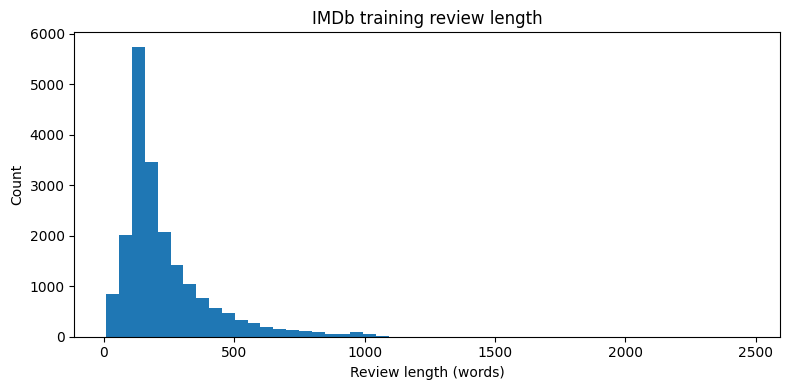

In [2]:
dataset = load_dataset("stanfordnlp/imdb")

train_full = pd.DataFrame({
    "text": dataset["train"]["text"],
    "label": dataset["train"]["label"]
})
test_df = pd.DataFrame({
    "text": dataset["test"]["text"],
    "label": dataset["test"]["label"]
})

train_df, val_df = train_test_split(
    train_full,
    test_size=0.2,
    random_state=SEED,
    stratify=train_full["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

lengths = train_df["text"].str.split().str.len()
dataset_stats = pd.DataFrame({
    "metric": [
        "train samples", "validation samples", "test samples",
        "classes", "missing text", "missing labels",
        "duplicate train texts", "mean review length", "median review length"
    ],
    "value": [
        len(train_df), len(val_df), len(test_df),
        train_df["label"].nunique(), train_df["text"].isna().sum(),
        train_df["label"].isna().sum(), train_df["text"].duplicated().sum(),
        lengths.mean(), lengths.median()
    ]
})
display(dataset_stats)
dataset_stats.to_csv(os.path.join(OUTPUT_DIR, "dataset_statistics.csv"), index=False)

plt.figure(figsize=(8, 4))
plt.hist(lengths, bins=50)
plt.xlabel("Review length (words)")
plt.ylabel("Count")
plt.title("IMDb training review length")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "sequence_length_distribution.png"), dpi=160)
plt.show()

## 5. Tokenization, vocabulary và padding

Tokenizer và cách tạo vocabulary giữ theo LAB 05. Hai token đặc biệt được dành riêng: `<PAD>` có ID 0 và `<UNK>` có ID 1. Vocabulary chỉ học từ `train_df`; từ ngoài vocabulary được ánh xạ thành `<UNK>`. Mỗi review được cắt hoặc đệm đến `max_length`.

In [3]:
def tokenize(text):
    return re.findall(r"\b\w+\b|[^\w\s]", str(text).lower())

PAD_ID, UNK_ID = 0, 1
counter = Counter(token for text in train_df["text"] for token in tokenize(text))
vocab = {"<PAD>": PAD_ID, "<UNK>": UNK_ID}
vocab.update({
    word: index + 2
    for index, (word, _) in enumerate(counter.most_common(VOCAB_SIZE - 2))
})
VOCAB_SIZE_ACTUAL = len(vocab)

def encode_text(text, max_length):
    ids = [vocab.get(token, UNK_ID) for token in tokenize(text)[:max_length]]
    return ids + [PAD_ID] * (max_length - len(ids))

class ReviewDataset(Dataset):
    def __init__(self, frame, max_length):
        self.texts = frame["text"].tolist()
        self.labels = frame["label"].astype(int).tolist()
        self.max_length = max_length

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        ids = torch.tensor(
            encode_text(self.texts[index], self.max_length),
            dtype=torch.long
        )
        label = torch.tensor(self.labels[index], dtype=torch.long)
        return ids, label

def make_loaders(max_length, batch_size=BATCH_SIZE):
    train_loader = DataLoader(
        ReviewDataset(train_df, max_length),
        batch_size=batch_size,
        shuffle=True
    )
    val_loader = DataLoader(
        ReviewDataset(val_df, max_length),
        batch_size=batch_size
    )
    test_loader = DataLoader(
        ReviewDataset(test_df, max_length),
        batch_size=batch_size
    )
    return train_loader, val_loader, test_loader

print("Vocabulary size:", VOCAB_SIZE_ACTUAL)

Vocabulary size: 20000


## 6. Positional Encoding

Self-attention không tự biểu diễn vị trí trước/sau của token. Positional Encoding hình sin/cos được cộng vào embedding để cung cấp positional information.

Với vị trí `pos`, chiều chẵn dùng sin và chiều lẻ dùng cos:

\[
PE(pos,2i)=\sin\left(\frac{pos}{10000^{2i/d_{model}}}\right)
\]

\[
PE(pos,2i+1)=\cos\left(\frac{pos}{10000^{2i/d_{model}}}\right)
\]

Tensor positional encoding có shape `(1, max_length, d_model)` và được broadcast theo batch.

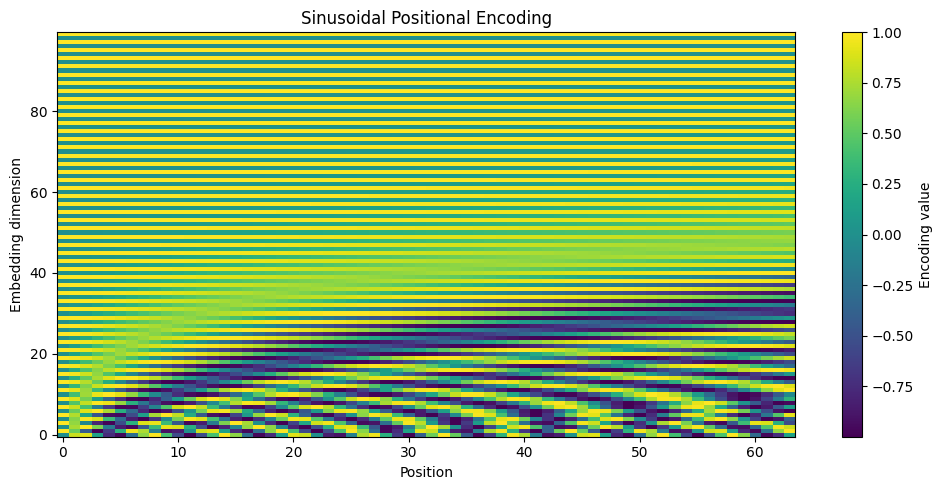

,dim_0,dim_1,dim_2,dim_3,dim_4,dim_5,dim_6,dim_7
0,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000
1,0.841471,0.540302,0.739121,0.673573,0.637948,0.770079,0.544204,0.838953
2,0.909297,-0.416147,0.995704,-0.092598,0.982541,0.186044,0.913123,0.407684
3,0.141120,-0.989992,0.602238,-0.798317,0.875321,-0.483542,0.987931,-0.154897
4,-0.756802,-0.653644,-0.184401,-0.982851,0.365592,-0.930775,0.744532,-0.667587


In [4]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_length=512):
        super().__init__()
        position = torch.arange(max_length, dtype=torch.float32).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float32)
            * (-math.log(10000.0) / d_model)
        )
        pe = torch.zeros(max_length, d_model)
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term[:pe[:, 1::2].shape[1]])
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]

pe_layer = PositionalEncoding(D_MODEL, max_length=MAX_LENGTH)
pe_values = pe_layer.pe[0].cpu().numpy()

plt.figure(figsize=(10, 5))
plt.imshow(pe_values[:64].T, aspect="auto", origin="lower", cmap="viridis")
plt.xlabel("Position")
plt.ylabel("Embedding dimension")
plt.title("Sinusoidal Positional Encoding")
plt.colorbar(label="Encoding value")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "positional_encoding.png"), dpi=160)
plt.show()

position_table = pd.DataFrame(
    pe_values[:5],
    columns=[f"dim_{i}" for i in range(D_MODEL)]
)
display(position_table.iloc[:, :8])

## 7. Multi-Head Self-Attention

Từ LAB 06, Scaled Dot-Product Attention được tính theo:

\[
Attention(Q,K,V)=softmax\left(\frac{QK^T}{\sqrt{d_k}}\right)V
\]

Với input `X` có shape `(B,T,d_model)`, các phép chiếu tuyến tính tạo Q, K, V. Sau đó tách thành `n_heads`; mỗi head có `d_k = d_model / n_heads`.

- Q, K, V: `(B, n_heads, T, d_k)`
- Attention scores: `(B, n_heads, T, T)`
- Attention output sau ghép heads và chiếu đầu ra: `(B,T,d_model)`

Padding mask được áp dụng lên các key trước softmax để attention không phân bổ trọng số vào token padding.

In [5]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads, dropout=0.1):
        super().__init__()
        if d_model % n_heads != 0:
            raise ValueError("d_model phải chia hết cho n_heads")
        self.d_model = d_model
        self.n_heads = n_heads
        self.d_k = d_model // n_heads
        self.q_proj = nn.Linear(d_model, d_model)
        self.k_proj = nn.Linear(d_model, d_model)
        self.v_proj = nn.Linear(d_model, d_model)
        self.out_proj = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, padding_mask=None, return_attention=False):
        batch_size, seq_length, _ = x.shape
        q = self.q_proj(x).view(
            batch_size, seq_length, self.n_heads, self.d_k
        ).transpose(1, 2)
        k = self.k_proj(x).view(
            batch_size, seq_length, self.n_heads, self.d_k
        ).transpose(1, 2)
        v = self.v_proj(x).view(
            batch_size, seq_length, self.n_heads, self.d_k
        ).transpose(1, 2)

        scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(self.d_k)
        if padding_mask is not None:
            scores = scores.masked_fill(
                ~padding_mask[:, None, None, :],
                torch.finfo(scores.dtype).min
            )

        attention = torch.softmax(scores, dim=-1)
        attention = self.dropout(attention)
        context = torch.matmul(attention, v)
        context = context.transpose(1, 2).contiguous().view(
            batch_size, seq_length, self.d_model
        )
        output = self.out_proj(context)

        if return_attention:
            return output, attention
        return output

## 8. Transformer Encoder Block

Một block gồm hai nhánh residual:

1. Multi-Head Self-Attention → Dropout → cộng input → LayerNorm.
2. Feed-Forward Network (Linear → GELU → Linear) → Dropout → cộng nhánh trước → LayerNorm.

LayerNorm chuẩn hóa theo feature dimension. FFN biến đổi phi tuyến representation tại từng vị trí token.

In [6]:
class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.attention = MultiHeadSelfAttention(d_model, n_heads, dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Linear(d_ff, d_model)
        )
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, padding_mask=None, return_attention=False):
        if return_attention:
            attention_output, attention_weights = self.attention(
                x, padding_mask, return_attention=True
            )
        else:
            attention_output = self.attention(x, padding_mask)

        x = self.norm1(x + self.dropout(attention_output))
        ffn_output = self.ffn(x)
        output = self.norm2(x + self.dropout(ffn_output))

        if return_attention:
            return output, attention_weights
        return output

class TransformerClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        d_model=100,
        n_heads=4,
        d_ff=256,
        max_length=128,
        dropout=0.3,
        pad_id=PAD_ID
    ):
        super().__init__()
        self.embedding = nn.Embedding(
            vocab_size, d_model, padding_idx=pad_id
        )
        self.position = PositionalEncoding(d_model, max_length)
        self.embedding_dropout = nn.Dropout(dropout)
        self.block = TransformerBlock(d_model, n_heads, d_ff, dropout)
        self.classifier = nn.Linear(d_model, 2)
        self.pad_id = pad_id

    def forward(self, ids, return_attention=False):
        padding_mask = ids.ne(self.pad_id)
        x = self.embedding(ids) * math.sqrt(self.embedding.embedding_dim)
        x = self.position(x)
        x = self.embedding_dropout(x)

        if return_attention:
            hidden, attention = self.block(
                x, padding_mask, return_attention=True
            )
        else:
            hidden = self.block(x, padding_mask)

        mask = padding_mask.unsqueeze(-1).to(hidden.dtype)
        pooled = (hidden * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)
        logits = self.classifier(pooled)

        if return_attention:
            return logits, attention, padding_mask
        return logits

class LSTMClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim=100,
        hidden_size=128,
        dropout=0.3,
        pad_id=PAD_ID
    ):
        super().__init__()
        self.embedding = nn.Embedding(
            vocab_size, embedding_dim, padding_idx=pad_id
        )
        self.lstm = nn.LSTM(
            embedding_dim, hidden_size, batch_first=True
        )
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_size, 2)

    def forward(self, ids):
        embedded = self.embedding(ids)
        _, (hidden, _) = self.lstm(embedded)
        return self.classifier(self.dropout(hidden[-1]))

## 9. Kiểm tra shape của Transformer Block

Với `B=8`, `T=100`, `d_model=128`, `n_heads=4`, ta có `d_k=32`. Q, K, V có shape `(8,4,100,32)` và attention scores có shape `(8,4,100,100)`.

In [7]:
shape_model = MultiHeadSelfAttention(128, 4)
shape_input = torch.randn(8, 100, 128)
shape_mask = torch.ones(8, 100, dtype=torch.bool)
with torch.no_grad():
    shape_output, shape_attention = shape_model(
        shape_input, shape_mask, return_attention=True
    )
print("Input:", shape_input.shape)
print("Q/K/V:", (8, 4, 100, 32))
print("Attention scores:", shape_attention.shape)
print("Output:", shape_output.shape)
assert shape_attention.shape == (8, 4, 100, 100)
assert shape_output.shape == (8, 100, 128)

Input: torch.Size([8, 100, 128])
Q/K/V: (8, 4, 100, 32)
Attention scores: torch.Size([8, 4, 100, 100])
Output: torch.Size([8, 100, 128])


## 10. Hàm huấn luyện và đánh giá

Hai mô hình được đánh giá trên cùng test set. Mỗi epoch theo dõi train loss và validation loss. Checkpoint có validation F1 tốt nhất được dùng để đánh giá test. Thời gian huấn luyện và số tham số được ghi lại trong bảng kết quả.

In [8]:
def calculate_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0)
    }

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss = 0.0
    all_labels, all_predictions = [], []

    for ids, labels in loader:
        ids = ids.to(DEVICE)
        labels = labels.to(DEVICE)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            logits = model(ids)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()

        total_loss += loss.item() * labels.size(0)
        all_labels.extend(labels.detach().cpu().numpy())
        all_predictions.extend(logits.argmax(dim=1).detach().cpu().numpy())

    return (
        total_loss / len(loader.dataset),
        np.asarray(all_labels),
        np.asarray(all_predictions)
    )

def train_classifier(model, max_length, epochs=EPOCHS, batch_size=BATCH_SIZE):
    train_loader, val_loader, test_loader = make_loaders(
        max_length, batch_size
    )
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    criterion = nn.CrossEntropyLoss()
    history = []
    best_state = None
    best_f1 = -1
    start_time = time.time()

    for epoch in range(1, epochs + 1):
        train_loss, train_y, train_pred = run_epoch(
            model, train_loader, criterion, optimizer
        )
        val_loss, val_y, val_pred = run_epoch(
            model, val_loader, criterion
        )
        train_metrics = calculate_metrics(train_y, train_pred)
        val_metrics = calculate_metrics(val_y, val_pred)

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "train_accuracy": train_metrics["accuracy"],
            "val_accuracy": val_metrics["accuracy"],
            "train_f1": train_metrics["f1"],
            "val_f1": val_metrics["f1"]
        })

        if val_metrics["f1"] > best_f1:
            best_f1 = val_metrics["f1"]
            best_state = copy.deepcopy(model.state_dict())

        print(
            f"Epoch {epoch}/{epochs} | "
            f"train_loss={train_loss:.4f} | "
            f"val_loss={val_loss:.4f} | "
            f"val_f1={val_metrics['f1']:.4f}"
        )

    model.load_state_dict(best_state)
    elapsed = time.time() - start_time
    test_loss, test_y, test_pred = run_epoch(
        model, test_loader, criterion
    )
    metrics = calculate_metrics(test_y, test_pred)

    result = {
        "parameters": sum(p.numel() for p in model.parameters()),
        "training_time_sec": elapsed,
        "test_loss": test_loss,
        **metrics
    }
    return model, pd.DataFrame(history), result, (test_y, test_pred)

## 11. Thực nghiệm chính — LSTM và Transformer

Hai mô hình dùng cùng embedding dimension 100, batch size, optimizer Adam, learning rate, số epoch và các tập dữ liệu. Kiến trúc LSTM lấy hidden state cuối; Transformer dùng positional encoding, một Transformer Encoder Block và masked mean pooling.

In [9]:
train_loader, val_loader, test_loader = make_loaders(MAX_LENGTH)

lstm_model, lstm_history, lstm_result, lstm_predictions = train_classifier(
    LSTMClassifier(
        VOCAB_SIZE_ACTUAL,
        embedding_dim=EMBEDDING_DIM,
        hidden_size=HIDDEN_SIZE,
        dropout=DROPOUT
    ),
    MAX_LENGTH
)

transformer_model, transformer_history, transformer_result, transformer_predictions = train_classifier(
    TransformerClassifier(
        VOCAB_SIZE_ACTUAL,
        d_model=D_MODEL,
        n_heads=N_HEADS,
        d_ff=D_FF,
        max_length=MAX_LENGTH,
        dropout=DROPOUT
    ),
    MAX_LENGTH
)

main_results = pd.DataFrame([
    {"model": "LSTM", "max_length": MAX_LENGTH, **lstm_result},
    {"model": "Transformer", "max_length": MAX_LENGTH, **transformer_result}
])
display(main_results)
main_results.to_csv(os.path.join(OUTPUT_DIR, "results.csv"), index=False)

Epoch 1/3 | train_loss=0.6884 | val_loss=0.6586 | val_f1=0.6449
Epoch 2/3 | train_loss=0.6529 | val_loss=0.6357 | val_f1=0.6137
Epoch 3/3 | train_loss=0.5938 | val_loss=0.6119 | val_f1=0.7217
Epoch 1/3 | train_loss=0.6431 | val_loss=0.6083 | val_f1=0.6287
Epoch 2/3 | train_loss=0.5804 | val_loss=0.5524 | val_f1=0.7319
Epoch 3/3 | train_loss=0.5489 | val_loss=0.5370 | val_f1=0.7543


,model,max_length,parameters,training_time_sec,test_loss,accuracy,precision,recall,f1
0,LSTM,128,2118018,223.639244,0.619838,0.66924,0.630740,0.81648,0.711691
1,Transformer,128,2092558,979.155689,0.536904,0.73928,0.718481,0.78688,0.751126


## 12. Learning curves

Đường loss train và validation cho biết quá trình hội tụ. Nếu train loss tiếp tục giảm trong khi validation loss tăng, có thể xuất hiện overfitting.

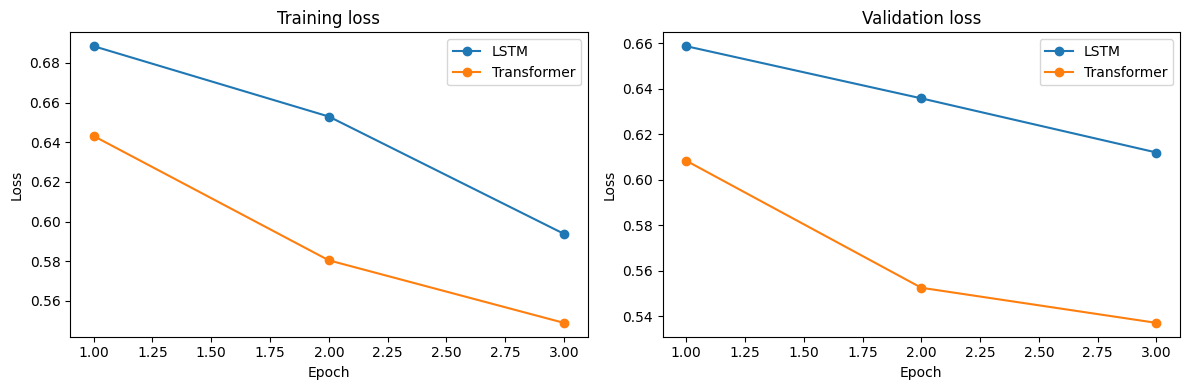

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, history in [
    ("LSTM", lstm_history),
    ("Transformer", transformer_history)
]:
    axes[0].plot(history["epoch"], history["train_loss"], marker="o", label=name)
    axes[1].plot(history["epoch"], history["val_loss"], marker="o", label=name)

axes[0].set_title("Training loss")
axes[1].set_title("Validation loss")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "learning_curves.png"), dpi=160)
plt.show()

learning_history = pd.concat([
    lstm_history.assign(model="LSTM"),
    transformer_history.assign(model="Transformer")
], ignore_index=True)
learning_history.to_csv(
    os.path.join(OUTPUT_DIR, "learning_curves.csv"),
    index=False
)

## 13. Confusion Matrix và classification report

Confusion matrix được tạo cho Transformer trên test set. Các chỉ số Accuracy, Precision, Recall và F1 được tính từ dự đoán test, không lấy từ tập train.

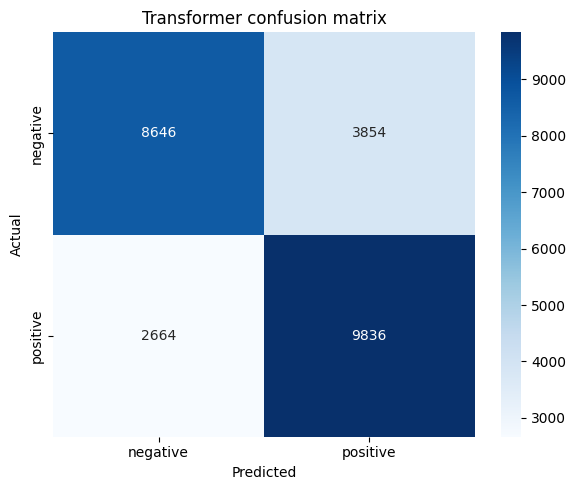

              precision    recall  f1-score   support

    negative       0.76      0.69      0.73     12500
    positive       0.72      0.79      0.75     12500

    accuracy                           0.74     25000
   macro avg       0.74      0.74      0.74     25000
weighted avg       0.74      0.74      0.74     25000



In [11]:
y_true, y_pred = transformer_predictions
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["negative", "positive"],
    yticklabels=["negative", "positive"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Transformer confusion matrix")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "confusion_matrix.png"), dpi=160)
plt.show()

print(classification_report(
    y_true,
    y_pred,
    target_names=["negative", "positive"],
    zero_division=0
))

## 14. Thực nghiệm số lượng attention heads

Giữ cố định `d_model=100` là không chia hết cho 8; do đó thí nghiệm này dùng `d_model=128` để kiểm tra đủ 1, 2, 4 và 8 heads như LAB 07. `d_k = d_model / n_heads`. Mỗi cấu hình được huấn luyện trong một epoch để khảo sát nhanh; kết quả của thí nghiệm này không thay thế phép so sánh chính.

In [12]:
HEADS_D_MODEL = 128
HEADS_D_FF = 256
HEADS_EPOCHS = 1
HEADS_MAX_LENGTH = 128
head_rows = []

for heads in [1, 2, 4, 8]:
    head_model = TransformerClassifier(
        VOCAB_SIZE_ACTUAL,
        d_model=HEADS_D_MODEL,
        n_heads=heads,
        d_ff=HEADS_D_FF,
        max_length=HEADS_MAX_LENGTH,
        dropout=DROPOUT
    )
    trained, history, result, predictions = train_classifier(
        head_model,
        HEADS_MAX_LENGTH,
        epochs=HEADS_EPOCHS
    )
    head_rows.append({
        "n_heads": heads,
        "d_model": HEADS_D_MODEL,
        "d_k": HEADS_D_MODEL // heads,
        **result
    })

head_results = pd.DataFrame(head_rows)
display(head_results)
head_results.to_csv(
    os.path.join(OUTPUT_DIR, "attention_heads_results.csv"),
    index=False
)

Epoch 1/1 | train_loss=0.6513 | val_loss=0.6076 | val_f1=0.6637
Epoch 1/1 | train_loss=0.6425 | val_loss=0.5930 | val_f1=0.6692
Epoch 1/1 | train_loss=0.6347 | val_loss=0.5584 | val_f1=0.7051
Epoch 1/1 | train_loss=0.6190 | val_loss=0.5839 | val_f1=0.6798


,n_heads,d_model,d_k,parameters,training_time_sec,test_loss,accuracy,precision,recall,f1
0,1,128,128,2692738,240.657785,0.613039,0.66940,0.691024,0.61280,0.649565
1,2,128,64,2692738,276.136597,0.599559,0.68600,0.719671,0.60936,0.659938
2,4,128,32,2692738,337.388082,0.562733,0.70640,0.724739,0.66560,0.693912
3,8,128,16,2692738,453.021780,0.592250,0.70388,0.767166,0.58544,0.664095


## 15. Visualize attention heads

Attention matrix được lấy từ một review trong test set. Hình vẽ chỉ thể hiện phân phối attention weights của từng head. Không gán nhãn cú pháp/ngữ nghĩa cho head nếu chưa có bằng chứng độc lập; attention weights không tự động là lời giải thích cho quyết định của mô hình.

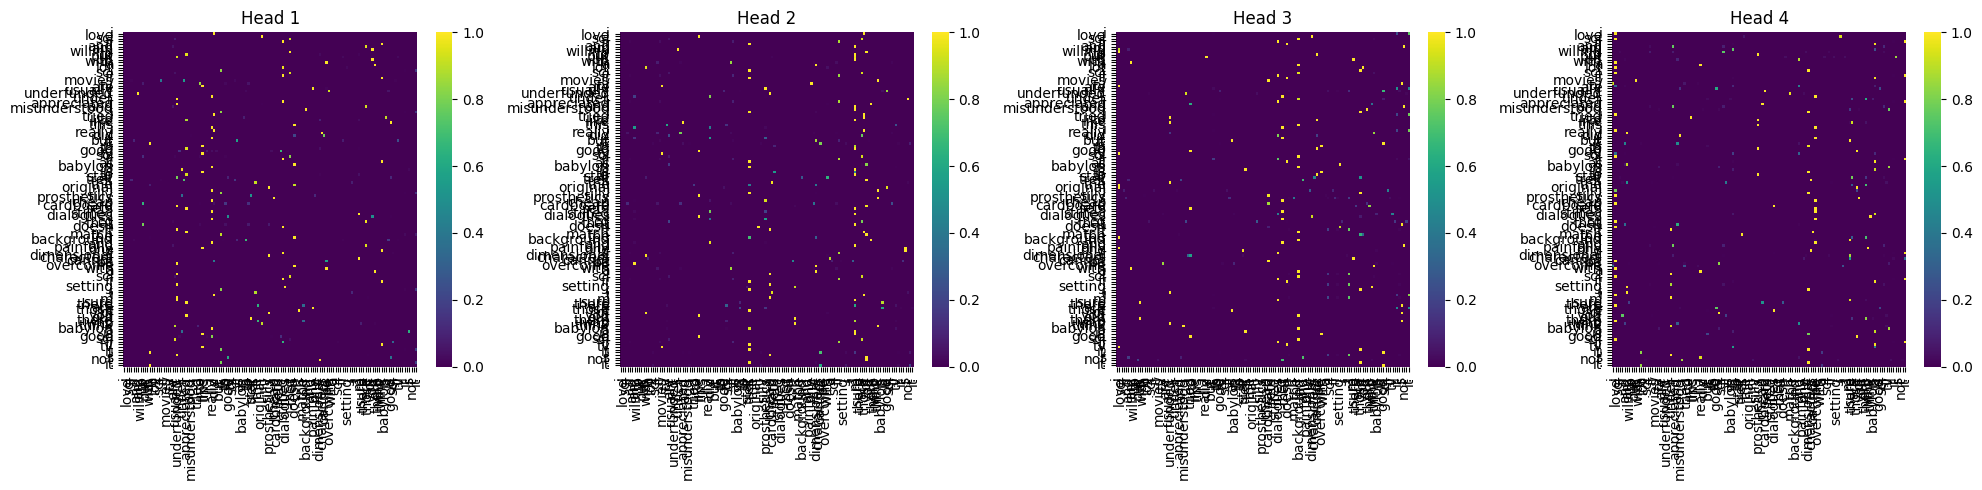

,head_a,head_b,correlation
0,1,2,0.007951
1,1,3,-0.007505
2,1,4,-0.008844
3,2,3,-0.000712
4,2,4,-0.008241
5,3,4,0.003362


In [13]:
sample_text = test_df.iloc[0]["text"]
sample_tokens = tokenize(sample_text)[:MAX_LENGTH]
sample_ids = torch.tensor(
    [encode_text(sample_text, MAX_LENGTH)],
    dtype=torch.long,
    device=DEVICE
)

transformer_model.eval()
with torch.no_grad():
    sample_logits, sample_attention, sample_mask = transformer_model(
        sample_ids,
        return_attention=True
    )

valid_length = int(sample_mask[0].sum().item())
attention_array = sample_attention[0, :, :valid_length, :valid_length].cpu().numpy()

fig, axes = plt.subplots(1, N_HEADS, figsize=(5 * N_HEADS, 5))
if N_HEADS == 1:
    axes = [axes]
for head_index, ax in enumerate(axes):
    sns.heatmap(
        attention_array[head_index],
        ax=ax,
        cmap="viridis",
        xticklabels=sample_tokens[:valid_length],
        yticklabels=sample_tokens[:valid_length]
    )
    ax.set_title(f"Head {head_index + 1}")
    ax.tick_params(axis="x", labelrotation=90)
    ax.tick_params(axis="y", labelrotation=0)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "attention_heads.png"), dpi=160)
plt.show()

head_similarity = []
for i in range(N_HEADS):
    for j in range(i + 1, N_HEADS):
        a = attention_array[i].flatten()
        b = attention_array[j].flatten()
        similarity = np.corrcoef(a, b)[0, 1]
        head_similarity.append({
            "head_a": i + 1,
            "head_b": j + 1,
            "correlation": similarity
        })

head_similarity_df = pd.DataFrame(head_similarity)
display(head_similarity_df)
head_similarity_df.to_csv(
    os.path.join(OUTPUT_DIR, "attention_head_similarity.csv"),
    index=False
)

## 16. Thực nghiệm sequence length

LAB 07 yêu cầu khảo sát `max_length = 32, 64, 128, 256`. Mỗi cấu hình được huấn luyện một epoch để so sánh ảnh hưởng của độ dài sequence. Số phần tử của attention matrix trên mỗi head tăng theo \(T^2\): khi T tăng gấp đôi, số phần tử tăng gấp bốn.

Epoch 1/1 | train_loss=0.6781 | val_loss=0.6544 | val_f1=0.6015
Epoch 1/1 | train_loss=0.6642 | val_loss=0.6155 | val_f1=0.6669
Epoch 1/1 | train_loss=0.6469 | val_loss=0.5726 | val_f1=0.7151
Epoch 1/1 | train_loss=0.6070 | val_loss=0.5447 | val_f1=0.7117


,max_length,mean_tokens_retained,attention_elements_per_head,parameters,training_time_sec,test_loss,accuracy,precision,recall,f1
0,32,31.99005,1024,2092558,46.679568,0.657458,0.59880,0.607541,0.55816,0.581805
1,64,63.69865,4096,2092558,117.474811,0.618562,0.65412,0.650402,0.66648,0.658343
2,128,122.94335,16384,2092558,378.266084,0.582740,0.69316,0.679690,0.73064,0.704245
3,256,201.90500,65536,2092558,1051.178850,0.553077,0.73204,0.782452,0.64280,0.705784


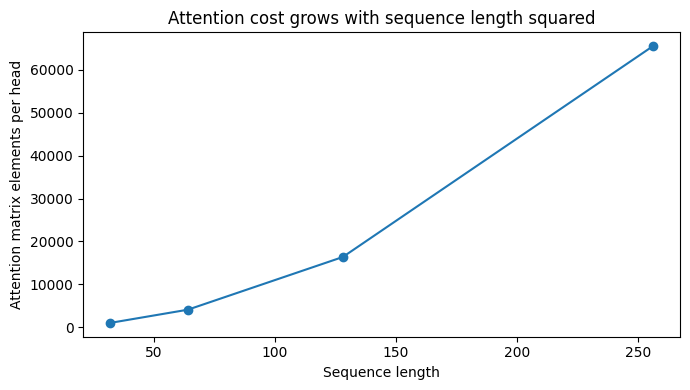

In [14]:
LENGTH_EPOCHS = 1
length_rows = []

for seq_length in [32, 64, 128, 256]:
    length_model = TransformerClassifier(
        VOCAB_SIZE_ACTUAL,
        d_model=D_MODEL,
        n_heads=N_HEADS,
        d_ff=D_FF,
        max_length=seq_length,
        dropout=DROPOUT
    )
    trained, history, result, predictions = train_classifier(
        length_model,
        seq_length,
        epochs=LENGTH_EPOCHS
    )
    retained = np.minimum(
        train_df["text"].apply(lambda x: len(tokenize(x))).to_numpy(),
        seq_length
    ).mean()
    length_rows.append({
        "max_length": seq_length,
        "mean_tokens_retained": retained,
        "attention_elements_per_head": seq_length ** 2,
        **result
    })

length_results = pd.DataFrame(length_rows)
display(length_results)
length_results.to_csv(
    os.path.join(OUTPUT_DIR, "sequence_length_results.csv"),
    index=False
)

plt.figure(figsize=(7, 4))
plt.plot(
    length_results["max_length"],
    length_results["attention_elements_per_head"],
    marker="o"
)
plt.xlabel("Sequence length")
plt.ylabel("Attention matrix elements per head")
plt.title("Attention cost grows with sequence length squared")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "sequence_length_cost.png"), dpi=160)
plt.show()

## 17. Error analysis

Bảng dưới đây lấy ba mẫu dự đoán đúng và ba mẫu dự đoán sai từ test set của Transformer. Việc phân loại nguyên nhân (negation, contrast, long sequence, rare word, ambiguity, truncation, noise...) cần được kiểm tra thủ công theo nội dung thực tế; không tự động gán nguyên nhân chỉ dựa trên nhãn đúng/sai.

In [15]:
error_df = test_df[["text", "label"]].copy()
error_df["predicted"] = y_pred
error_df["actual_label"] = error_df["label"].map({
    0: "negative", 1: "positive"
})
error_df["predicted_label"] = error_df["predicted"].map({
    0: "negative", 1: "positive"
})
error_df["correct"] = error_df["label"].to_numpy() == y_pred

correct_examples = error_df[error_df["correct"]].head(3).copy()
incorrect_examples = error_df[~error_df["correct"]].head(3).copy()
error_examples = pd.concat(
    [correct_examples, incorrect_examples],
    ignore_index=True
)
error_examples["manual_error_category"] = ""
display(error_examples[[
    "text", "actual_label", "predicted_label",
    "correct", "manual_error_category"
]])
error_examples.to_csv(
    os.path.join(OUTPUT_DIR, "error_analysis.csv"),
    index=False
)

,text,actual_label,predicted_label,correct,manual_error_category
0,its a totally average film with a few semi-alr...,negative,negative,True,
1,STAR RATING: ***** Saturday Night **** Friday ...,negative,negative,True,
2,"It actually pains me to say it, but this movie...",negative,negative,True,
3,I love sci-fi and am willing to put up with a ...,negative,positive,False,
4,"Worth the entertainment value of a rental, esp...",negative,positive,False,
5,"First off let me say, If you haven't enjoyed a...",negative,positive,False,


## 18. Kiểm thử dự đoán

Các trường hợp kiểm thử gồm câu ngắn, câu dài, phủ định, tương phản và cảm xúc không rõ ràng. Kết quả là dự đoán của mô hình đã huấn luyện, không phải đáp án được gán thủ công.

In [16]:
def predict_sentiment(text):
    ids = torch.tensor(
        [encode_text(text, MAX_LENGTH)],
        dtype=torch.long,
        device=DEVICE
    )
    transformer_model.eval()
    with torch.no_grad():
        logits = transformer_model(ids)
        probabilities = torch.softmax(logits, dim=1)[0].cpu().numpy()

    predicted_id = int(probabilities.argmax())
    return {
        "text": text,
        "prediction": "positive" if predicted_id == 1 else "negative",
        "probability_negative": float(probabilities[0]),
        "probability_positive": float(probabilities[1]),
        "confidence": float(probabilities[predicted_id])
    }

test_sentences = [
    "I really enjoyed this movie.",
    "The film was long, slow, and difficult to follow, although the actors performed well.",
    "The movie was not good.",
    "I expected the movie to be bad, but it was surprisingly good.",
    "The movie had some good moments, but I am not sure whether I liked it."
]

prediction_results = pd.DataFrame([
    predict_sentiment(sentence) for sentence in test_sentences
])
display(prediction_results)
prediction_results.to_csv(
    os.path.join(OUTPUT_DIR, "sample_predictions.csv"),
    index=False
)

,text,prediction,probability_negative,probability_positive,confidence
0,I really enjoyed this movie.,negative,0.537034,0.462966,0.537034
1,"The film was long, slow, and difficult to foll...",positive,0.031228,0.968772,0.968772
2,The movie was not good.,negative,0.987024,0.012976,0.987024
3,"I expected the movie to be bad, but it was sur...",negative,0.967954,0.032046,0.967954
4,"The movie had some good moments, but I am not ...",positive,0.068100,0.931900,0.931900


## 19. Xuất các module Python

Hai module cốt lõi được trích xuất thành file `.py` trong thư mục deliverables để có thể tái sử dụng độc lập.

In [17]:
transformer_block_source = """import math
import torch
import torch.nn as nn

class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads, dropout=0.1):
        super().__init__()
        if d_model % n_heads != 0:
            raise ValueError("d_model phải chia hết cho n_heads")
        self.d_model = d_model
        self.n_heads = n_heads
        self.d_k = d_model // n_heads
        self.q_proj = nn.Linear(d_model, d_model)
        self.k_proj = nn.Linear(d_model, d_model)
        self.v_proj = nn.Linear(d_model, d_model)
        self.out_proj = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, padding_mask=None, return_attention=False):
        batch_size, seq_length, _ = x.shape
        q = self.q_proj(x).view(batch_size, seq_length, self.n_heads, self.d_k).transpose(1, 2)
        k = self.k_proj(x).view(batch_size, seq_length, self.n_heads, self.d_k).transpose(1, 2)
        v = self.v_proj(x).view(batch_size, seq_length, self.n_heads, self.d_k).transpose(1, 2)
        scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(self.d_k)
        if padding_mask is not None:
            scores = scores.masked_fill(~padding_mask[:, None, None, :], torch.finfo(scores.dtype).min)
        attention = torch.softmax(scores, dim=-1)
        context = self.dropout(attention) @ v
        context = context.transpose(1, 2).contiguous().view(batch_size, seq_length, self.d_model)
        output = self.out_proj(context)
        if return_attention:
            return output, attention
        return output

class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.attention = MultiHeadSelfAttention(d_model, n_heads, dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Linear(d_ff, d_model)
        )
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, padding_mask=None, return_attention=False):
        if return_attention:
            attention_output, attention_weights = self.attention(x, padding_mask, True)
        else:
            attention_output = self.attention(x, padding_mask)
        x = self.norm1(x + self.dropout(attention_output))
        output = self.norm2(x + self.dropout(self.ffn(x)))
        if return_attention:
            return output, attention_weights
        return output
"""

positional_encoding_source = """import math
import torch
import torch.nn as nn

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_length=512):
        super().__init__()
        position = torch.arange(max_length, dtype=torch.float32).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float32)
            * (-math.log(10000.0) / d_model)
        )
        pe = torch.zeros(max_length, d_model)
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term[:pe[:, 1::2].shape[1]])
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]
"""

with open(os.path.join(OUTPUT_DIR, "transformer_block.py"), "w", encoding="utf-8") as file:
    file.write(transformer_block_source)

with open(os.path.join(OUTPUT_DIR, "positional_encoding.py"), "w", encoding="utf-8") as file:
    file.write(positional_encoding_source)

print("Exported:", "transformer_block.py", "positional_encoding.py")


Exported: transformer_block.py positional_encoding.py
